# Chapter 5: Quantum Boltzmann Machines

*The Boltzmann machine is statistical mechanics turned into a learning algorithm: a Boltzmann distribution over binary units whose energy function is shaped until its samples reproduce the data, trained by comparing correlation functions of the data with those of the model. This chapter develops the classical theory, the restricted model with its conditional independence, the exact likelihood gradient and the contrastive-divergence approximation whose bias we measure against the exact gradient, and then replaces the energy by a Hamiltonian with non-commuting terms and the distribution by its Gibbs state. The quantum Boltzmann machine inherits the negative phase of the classical model unchanged, through the cyclicity of the trace, but its positive phase becomes an imaginary-time correlation function by Duhamel's formula, and the training rule of the literature is shown to be the gradient of a Golden--Thompson bound that cannot see the visible transverse fields. Exact computations on small models show that on classical data the likelihood drives the transverse fields to zero, so that the model falls back on its classical limit, while on quantum data the quantum relative entropy is a convex loss with a gradient of expectation values, Hamiltonians are recovered exactly from their thermal states, and the operator content of the model decides what can be learned. The last part treats the quantum computer's share of the work: the free-energy variational principle, the thermofield double, and the variational quantum thermalizer, which prepares a Gibbs state with the circuits of Chapter 4 and a classical latent distribution whose entropy is known in closed form. The chapter closes with the connections between the two trainable quantum models of the book.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

Every model of the preceding chapters was a function. The support-vector
machine of Chapter 2 and the quantum neural network of
Chapter 4 map an input $\vec{x}$ to a label or a number, the
QAOA of Chapter 3 maps a set of angles to an energy, and
training meant adjusting parameters until the function agreed with the
data at the training points. The *Boltzmann machine* of this
chapter is a different kind of object: a probability distribution. It is
trained not to reproduce a function but to reproduce the statistics of a
set of samples, so that new samples drawn from the model are
indistinguishable, as far as the model can tell, from the data. Models of
this kind are called *generative*, and the Boltzmann machine is
their oldest member, older than the neural networks of
Chapter 4 by a few years [Ackley1985,Smolensky1986].
The classical machine is developed at length in the chapter on
Boltzmann machines of the machine-learning text [MLbook], and
its use as a wave-function ansatz, the neural quantum state, in the
chapter on Boltzmann machines and generative models of the many-body
text [MBbook]; Section *Energy-based models and the Boltzmann machine* summarizes what this
chapter needs from the first.

The reason it belongs in a book on quantum machine learning for
physicists is that the Boltzmann machine *is* statistical
mechanics, and the reader of the companion volume [QCbook] will
meet here, as learning problems, the objects of its many-body primer
and of its chapter on mapping Hamiltonians to qubits: Pauli-string
Hamiltonians, the transverse-field Ising and Heisenberg chains,
thermal states and partial traces. Its distribution is the Boltzmann distribution of an energy
function of binary variables, its partition function is the obstacle to
training, its training rule compares correlation functions of the data
with correlation functions of the model, and the sampling methods used
to estimate the latter are the Monte Carlo methods of spin systems. The
*quantum Boltzmann machine* (QBM) [Amin2018] takes the last step
that a physicist would take: it replaces the classical energy by a
Hamiltonian with non-commuting terms, the Boltzmann distribution by the
thermal (Gibbs) state $\rho=e^{-\beta H}/Z$, and the probability of a
configuration by the Born rule. The model is then a quantum many-body
system at finite temperature, and the questions of this book acquire a
new form. What does the non-commutativity buy when the data are
classical bit strings? What can be learned when the data are themselves
quantum states? And how does one prepare a Gibbs state, rather than a
ground state, on a quantum computer?

The chapter answers these questions in order, and the answers are
mixed in a way that is instructive. Section *Energy-based models and the Boltzmann machine* develops the
classical theory: energy-based models, the restricted Boltzmann
machine, the exact gradient of the likelihood, and the contrastive
divergence approximation that made the model practical, with its bias
measured against the exact gradient on problems small enough to
enumerate. Section *The quantum Boltzmann machine* defines the quantum model and
derives its gradient, which is where the non-commutativity bites: the
derivative of $e^{-\beta H}$ with respect to a coupling is no longer an
expectation value but an integral over imaginary time (Duhamel's
formula), and the practical training rule of the literature is the
gradient of an upper bound on the loss rather than of the loss itself.
Section *Boltzmann machines on classical data* trains both models on classical data and
finds, as the exact computation must, that the transverse fields which
make the model quantum are driven to zero: a classical distribution is
best fit by a classical model. Section *Learning quantum states* turns to
quantum data, where the picture reverses. When the target is a density
matrix, the quantum relative entropy is a convex loss whose gradient is
a difference of expectation values, a Hamiltonian in the model family
is recovered exactly from its Gibbs state, and a Hamiltonian outside it
is approximated only as well as the operator content of the model
allows. Section *Preparing Gibbs states on a quantum computer* is about the quantum computer's part
of the job: the variational principle for the free energy, the
thermofield double, and the variational quantum thermalizer, which
prepares a Gibbs state with the circuits of Chapter 4 and a
classical latent distribution. Section *Connections* places
the QBM next to the QNN and next to the transverse-field Ising model
that has accompanied us since Chapter 3, and
Section *Summary and perspectives* closes the chapter.

As in the previous chapters, every number is computed by a program in
`BookPrograms/chapter5/`, and all models are small enough
(at most seven qubits) for every quantity, including the partition
function and the exact gradient, to be evaluated by dense linear
algebra. This is deliberate. The approximations that make Boltzmann
machines usable at scale, classical and quantum, are approximations to
quantities we can here compute exactly, and the point of the chapter is
to see what they cost.


## Energy-based models and the Boltzmann machine

### Learning as the minimization of a divergence

The data are $N$ samples $\vec{v}^{(1)},\dots,\vec{v}^{(N)}$ of a vector
of $n_v$ binary variables, $\vec{v}\in\{0,1\}^{n_v}$, drawn from an
unknown distribution $\pi(\vec{v})$; the model is a family of
distributions $p_{\vec{\theta}}(\vec{v})$ over the same $2^{n_v}$
configurations. The natural measure of the distance from the data to
the model is the Kullback--Leibler divergence

$$
\mathrm{KL}(\pi\,\|\,p_{\vec{\theta}})
=\sum_{\vec{v}}\pi(\vec{v})\ln\frac{\pi(\vec{v})}{p_{\vec{\theta}}(\vec{v})}
=-S(\pi)-\sum_{\vec{v}}\pi(\vec{v})\ln p_{\vec{\theta}}(\vec{v}) ,\tag{5.1}
$$

which is non-negative and zero only when the two distributions
coincide. The first term, minus the entropy of the data, does not
depend on $\vec{\theta}$; the second is the expected negative
log-likelihood of the model under the data,

$$
\mathcal{L}(\vec{\theta})=-\sum_{\vec{v}}\pi(\vec{v})\ln p_{\vec{\theta}}(\vec{v})
\approx-\frac1N\sum_{k=1}^N\ln p_{\vec{\theta}}(\vec{v}^{(k)}) ,\tag{5.2}
$$

where the second form replaces the unknown $\pi$ by the empirical
distribution of the samples. Minimizing the divergence and maximizing
the likelihood are the same thing, and
$\mathcal{L}(\vec{\theta})-S(\pi)=\mathrm{KL}(\pi\|p_{\vec{\theta}})\ge0$
is the quantity we tabulate below: it is zero exactly when the model
has learned the data. On the toy distributions of this chapter $\pi$ is
known, so we can use Eq. (5.2) with the exact $\pi$ and
reserve the sampled form for the methods that need samples.

### Energy-based models

An energy-based model assigns to every configuration an energy
$E_{\vec{\theta}}(\vec{v})$ and defines the probabilities by the
Boltzmann distribution at unit temperature,

$$
p_{\vec{\theta}}(\vec{v})=\frac{e^{-E_{\vec{\theta}}(\vec{v})}}{Z(\vec{\theta})},
\qquad
Z(\vec{\theta})=\sum_{\vec{v}}e^{-E_{\vec{\theta}}(\vec{v})} .\tag{5.3}
$$

The temperature is not a separate parameter because it can be absorbed
into $\vec{\theta}$. Low-energy configurations are probable, and
learning means shaping the energy landscape so that its valleys sit on
the data. The gradient of the negative log-likelihood has a form that
every later formula of this chapter will echo:

$$
\frac{\partial\mathcal{L}}{\partial\theta_\mu}
=\sum_{\vec{v}}\pi(\vec{v})\frac{\partial E_{\vec{\theta}}(\vec{v})}{\partial\theta_\mu}
+\frac{\partial\ln Z}{\partial\theta_\mu}
=\Bigl\langle\frac{\partial E}{\partial\theta_\mu}\Bigr\rangle_{\rm data}
-\Bigl\langle\frac{\partial E}{\partial\theta_\mu}\Bigr\rangle_{\rm model} ,\tag{5.4}
$$

since $\partial_\mu\ln Z=-\sum_{\vec{v}}p_{\vec{\theta}}(\vec{v})\partial_\mu E(\vec{v})$.
Gradient descent lowers the energy of the data (the *positive
phase*) and raises the energy of what the model currently believes in
(the *negative phase*), and stops when the two averages agree. The
positive phase is a sum over the samples and costs nothing. The
negative phase is an expectation value under the model, which for
$n_v$ variables is a sum over $2^{n_v}$ configurations: it is the
partition function in disguise, and everything that is hard about
Boltzmann machines is in this term.

### The Boltzmann machine and its restricted form

A Boltzmann machine [Ackley1985] is an energy-based model with the
quadratic energy of an Ising model in the variables $\{0,1\}$,
$E(\vec{s})=-\sum_ia_is_i-\sum_{i<j}W_{ij}s_is_j$, in which only a subset
of the units, the *visible* units $\vec{v}$, carries data. The
remaining *hidden* units $\vec{h}\in\{0,1\}^{n_h}$ are summed
over, so that the model distribution of the visible units is the
marginal

$$
p_{\vec{\theta}}(\vec{v})=\sum_{\vec{h}}p_{\vec{\theta}}(\vec{v},\vec{h})
=\frac1Z\sum_{\vec{h}}e^{-E(\vec{v},\vec{h})} .\tag{5.5}
$$

Hidden units matter because a quadratic energy in the visible units
alone can only represent distributions with pairwise structure; the
parity distribution of two bits, which is the XOR problem of
Chapter 2 read as a distribution, is the standard
example of one it cannot. With hidden units the marginal of a quadratic
energy is a non-quadratic function of $\vec{v}$, and with enough hidden
units any distribution over $\{0,1\}^{n_v}$ can be approximated
[LeRoux2008].

The *restricted* Boltzmann machine (RBM) [Smolensky1986,Hinton2002]
keeps only the couplings between the two layers,

$$
E(\vec{v},\vec{h})=-\vec{a}\cdot\vec{v}-\vec{b}\cdot\vec{h}-\vec{v}^T\matr{W}\vec{h} ,\tag{5.6}
$$

with visible biases $\vec{a}\in\mathbb{R}^{n_v}$, hidden biases
$\vec{b}\in\mathbb{R}^{n_h}$ and weights $\matr{W}\in\mathbb{R}^{n_v\times n_h}$,
so that $\vec{\theta}=(\vec{a},\vec{b},\matr{W})$ has $n_v+n_h+n_vn_h$
components. The restriction is what makes the model usable. Because
no two hidden units interact, the hidden units are conditionally
independent given the visible ones, and vice versa,

$$
p(h_j=1\,|\,\vec{v})=\sigma\bigl(b_j+(\matr{W}^T\vec{v})_j\bigr),\qquad
p(v_i=1\,|\,\vec{h})=\sigma\bigl(a_i+(\matr{W}\vec{h})_i\bigr),\tag{5.7}
$$

with the logistic function $\sigma(x)=1/(1+e^{-x})$: the conditional
distribution of a layer factorizes, and a whole layer can be sampled at
once. The same independence lets the sum over the hidden units in
Eq. (5.5) be done in closed form,

$$
p_{\vec{\theta}}(\vec{v})=\frac{1}{Z}e^{-F(\vec{v})},\qquad
F(\vec{v})=-\vec{a}\cdot\vec{v}-\sum_{j=1}^{n_h}\ln\Bigl(1+e^{\,b_j+(\matr{W}^T\vec{v})_j}\Bigr) ,\tag{5.8}
$$

where $F(\vec{v})$ is called the free energy of the visible configuration
and $Z=\sum_{\vec{v}}e^{-F(\vec{v})}$. The model of the visible units is
therefore an energy-based model with the non-quadratic energy
$F(\vec{v})$; each hidden unit contributes a soft-plus function of a
linear combination of the visible bits, which is the sense in which an
RBM is a one-hidden-layer network. The gradient
Eq. (5.4) applied to Eq. (5.6) and
averaged over the hidden units gives the celebrated rule

$$
\begin{align}
\frac{\partial\mathcal{L}}{\partial W_{ij}}
&=\langle v_i\,p(h_j=1|\vec{v})\rangle_{\rm model}
-\langle v_i\,p(h_j=1|\vec{v})\rangle_{\rm data} ,
\nonumber\\
\frac{\partial\mathcal{L}}{\partial a_i}&=\langle v_i\rangle_{\rm model}-\langle v_i\rangle_{\rm data},
\qquad
\frac{\partial\mathcal{L}}{\partial b_j}=\langle p(h_j=1|\vec{v})\rangle_{\rm model}-\langle p(h_j=1|\vec{v})\rangle_{\rm data},
\end{align}
$$

in which the hidden units have been replaced by their conditional
means, which is exact. The three quantities inside the averages are
the sufficient statistics of the model; the data average runs over the
samples, the model average over $p_{\vec{\theta}}(\vec{v})$. For
$n_v\le20$ or so the model average can be computed by enumeration from
Eq. (5.8), and the class `RBM` of
`rbm.py` does exactly this: it stores $\vec{\theta}$ as one flat
vector, evaluates $\ln p(\vec{v})$ for all $2^{n_v}$ patterns with a
stable log-sum-exp, and returns the gradient Eq. (5.9)
as the difference of two weighted statistics vectors. The program checks
it against finite differences to $4\times10^{-10}$.

### Gibbs sampling and contrastive divergence

When $n_v$ is large the model average must be estimated by sampling,
and Eq. (5.7) gives the sampler: a *block Gibbs*
step draws all hidden units from $p(\vec{h}|\vec{v})$ and then all
visible units from $p(\vec{v}|\vec{h})$,

$$
\vec{v}_0\;\to\;\vec{h}_0\;\to\;\vec{v}_1\;\to\;\vec{h}_1\;\to\;\cdots\;\to\;\vec{v}_k ,\tag{5.10}
$$

and the chain converges to the model distribution
$p_{\vec{\theta}}(\vec{v})$ as $k\to\infty$ (the transition kernel has
$p_{\vec{\theta}}$ as its stationary distribution and is ergodic because
every configuration has non-zero probability). Running the chain to
equilibrium at every gradient step is expensive, and the mixing time
grows as the model learns and its energy valleys deepen.

Hinton's *contrastive divergence* (CD) [Hinton2002] is the
observation that one does not need equilibrium. Start the chain at the
data, $\vec{v}_0\sim\pi$, run it for $k$ steps, and use the
distribution $p_k$ of $\vec{v}_k$ in place of the model distribution in
the negative phase:

$$
\frac{\partial\mathcal{L}}{\partial\theta_\mu}
\;\approx\;
\Bigl\langle\frac{\partial E}{\partial\theta_\mu}\Bigr\rangle_{p_0}
-\Bigl\langle\frac{\partial E}{\partial\theta_\mu}\Bigr\rangle_{p_k}
\qquad(\text{CD-}k),\tag{5.11}
$$

with the hidden units again replaced by their conditional means. For
$k=1$ each gradient step costs one reconstruction of the data, and the
rule has an appealing reading: the model is pushed to make the data
more probable and its own one-step reconstruction of the data less
probable, so that the chain started at the data goes nowhere. The name
comes from the objective this rule approximately descends,

$$
\mathrm{CD}_k=\mathrm{KL}(p_0\,\|\,p_\infty)-\mathrm{KL}(p_k\,\|\,p_\infty) ,\tag{5.12}
$$

the difference of two divergences from the model: the first is the
likelihood objective Eq. (5.1) up to a constant, the second
is the divergence of the partially relaxed chain, and the difference is
non-negative and vanishes when the data distribution is stationary
under the chain, that is, when the model has learned the data. The
exact gradient of Eq. (5.12) contains, besides the
two averages of Eq. (5.11), a term from the dependence of
$p_k$ on $\vec{\theta}$ through the transition kernel, and CD drops it.
This is the approximation: CD-$k$ is not the gradient of any function,
and its fixed points are not the maximum of the likelihood
[CarreiraPerpinan2005,Bengio2009]. The bias decreases with $k$,
and it is small when the model is close to the data (the chain then
barely moves and both neglected quantities are small), which is why CD
works far better than it has any right to.

*Persistent* contrastive divergence (PCD) [Tieleman2008] removes
the restart: a set of chains is initialized once and advanced one
Gibbs step per parameter update, the negative phase being averaged over
the current chain states. If the parameters change slowly the chains
remain close to equilibrium, and the estimate approaches the true
gradient at the cost of a small learning rate and many chains. Both
estimators are implemented in `rbm.py` as
`gradient_cd` and `gradient_pcd`, on the same
statistics function as the exact gradient, so that the only difference
between the three is where the negative-phase configurations come from.

| Target | $n_h$ | exact | CD-1 | CD-10 | PCD |
|---|---|---|---|---|---|
| XOR ($n_v=2$) | 2 | 0.0044 | 0.0967 | 0.0228 | 0.0331 |
| bars and stripes ($n_v=4$) | 4 | 0.0230 | 0.0823 | 0.0531 | 0.4814 |

*Table 5.1: Classical RBMs on two toy distributions: the divergence
$\mathrm{KL}(\pi\|p_{\vec{\theta}})=\mathcal{L}-S(\pi)$ after 3000
steps of plain gradient descent (rate $0.5$) with the exact gradient,
contrastive divergence with $k=1$ and $k=10$ steps, and persistent CD
(rate $0.2$, 50 chains); CD and PCD see a data set of 200 samples of
$\pi$. XOR is the even-parity distribution on two bits, bars and
stripes the uniform distribution over the six $2\times2$ images whose
rows or columns are constant (patterns 0000, 0011, 1100, 1111, 0101,
1010). From `rbm.py`.*

![Left the divergence of Table 5.1 against the gradient step for the bar](../../BookFigures/chapter5/rbm.png)

*Figure 5.1: Left: the divergence of Table 5.1 against the gradient step for the bars-and-stripes RBM with the four estimators of the negative phase. Right: the learned distributions with the exact gradient and with CD-1 against the target. From `rbm.py`.*

Table 5.1 and Fig. 5.1 measure the estimators
on the two distributions that will be used throughout the chapter,
with the exact gradient as the reference. The exact gradient descends
smoothly and is still descending after 3000 steps (the RBM likelihood
has no finite maximum on a target with zero-probability patterns: the
weights must grow without bound to drive those probabilities to zero,
and the divergence of $0.02$ for bars and stripes is a matter of
patience, not of capacity). CD-1 stalls at a divergence four times
larger and its learned distribution, on the right of
Fig. 5.1, is visibly tilted: the bias of
Eq. (5.11) moves probability between the six patterns and
leaks some onto the ten others. CD-10 halves the gap, as the decreasing
bias with $k$ predicts. PCD with the learning rate and the 50 chains
of the table is the worst of the four and still fluctuating at the end,
a reminder that the persistent chains track the model only when the
parameters move slowly; with a tenth of the rate and ten times the
chains it overtakes CD-1 (Exercise 5.3). The point to retain
is not that one estimator is best but that all of them are
approximations to a quantity, the negative phase, that the quantum
model of the next section inherits unchanged, together with one new
difficulty of its own.

The listing below trains the XOR machine with the exact gradient and
with CD-1 from the same start, and prints the two divergences.


In [2]:
import numpy as np
from rbm import RBM, parity, kl_divergence

target = parity(2)                       # p(00) = p(11) = 1/2: the XOR distribution
for method in ["exact", "cd"]:
    rbm = RBM(n_visible=2, n_hidden=2, rng=0)
    hist = rbm.fit(target, method=method, k=1, steps=3000, lr=0.5)
    print(f"{method:>5}: KL(target || model) = {hist[-1]:.4f}, "
          f"p(v) = {np.round(rbm.probabilities(), 3)}")


exact: KL(target || model) = 0.0044, p(v) = [0.498 0.002 0.002 0.498]


   cd: KL(target || model) = 0.0967, p(v) = [0.294 0.003 0.003 0.7  ]


## The quantum Boltzmann machine

### Definition

A Boltzmann machine written in spin language has the energy
$E(\vec{z})=-\sum_i a_iz_i-\sum_{i<j}W_{ij}z_iz_j$ with $z_i=\pm1$, and
this energy is the diagonal of the Hamiltonian
$H=-\sum_ia_iZ_i-\sum_{i<j}W_{ij}Z_iZ_j$ in the computational basis.
The Boltzmann distribution Eq. (5.3) is the diagonal of the
Gibbs state $e^{-H}/Z$ of this Hamiltonian, and because $H$ is
diagonal the Gibbs state has nothing but a diagonal. The quantum
Boltzmann machine of Amin and coworkers [Amin2018] adds terms that
do not commute with the $Z$'s. In the form used in this chapter,

$$
H(\vec{\theta})=-\sum_{\mu=1}^P\theta_\mu\Lambda_\mu,\qquad
\rho(\vec{\theta})=\frac{e^{-\beta H(\vec{\theta})}}{Z(\vec{\theta})},\qquad
Z(\vec{\theta})=\mathrm{Tr}\,e^{-\beta H(\vec{\theta})} ,\tag{5.13}
$$

where the $\Lambda_\mu$ are Pauli strings on $n=n_v+n_h$ qubits chosen
once and for all, the $\theta_\mu$ are the trainable couplings and
$\beta$ is a fixed inverse temperature. The *restricted* QBM, the
analog of Eq. (5.6) drawn in Fig. 5.2,
takes

$$
H=-\sum_{i\in v}a_iZ_i-\sum_{j\in h}b_jZ_j-\sum_{i\in v}\sum_{j\in h}W_{ij}Z_iZ_j
-\sum_{q\in v\cup h}\Gamma_qX_q ,\tag{5.14}
$$

and the *transverse fields* $\Gamma_q$ are the only quantum
ingredient: with all $\Gamma_q=0$ the model is the classical RBM in
spin variables, $z_i=1-2v_i$. The data are measured in the
computational basis, so the probability the model assigns to a visible
configuration $\vec{v}$ is the Born-rule probability of the projector
onto that configuration of the visible qubits, with the hidden qubits
traced out:

$$
p_{\vec{\theta}}(\vec{v})=\mathrm{Tr}\bigl[\Pi_{\vec{v}}\,\rho(\vec{\theta})\bigr],\qquad
\Pi_{\vec{v}}=\vert\vec{v}\rangle\langle\vec{v}\vert\otimes I_h .\tag{5.15}
$$

Equation (5.15) is the counterpart of the marginal
Eq. (5.5): summing the diagonal of $\rho$ over the
hidden labels is the partial trace. Two things are new. The state
$\rho$ is not diagonal, so the model also assigns probabilities to
measurements in other bases, and a QBM with hidden units can leave the
visible qubits in a mixed state $\rho_v=\mathrm{Tr}_h\rho$ with
coherences; and the diagonal of $e^{-\beta H}$ is no longer
$e^{-\beta E(\vec{z})}$ for the quadratic energy of the model, or for
any energy built from its terms, because the matrix
exponential of a non-diagonal $H$ mixes configurations. The model
distribution over the visible bits is still a positive function on
$2^{n_v}$ points, and the question of this chapter is whether it is a
more useful family of such functions than the classical one. The loss
is the same negative log-likelihood Eq. (5.2) with
Eq. (5.15) inserted, and we keep calling it
$\mathcal{L}(\vec{\theta})$.

![The restricted quantum Boltzmann machine of Eq. 5.14 used for the bars](../../BookFigures/chapter5/5-rqbm.png)

*Figure 5.2: The restricted quantum Boltzmann machine of Eq. (5.14) used for the bars-and-stripes data in Section *Boltzmann machines on classical data*: four visible and three hidden qubits, $ZZ$ couplings $W_{ij}$ between the layers only, longitudinal fields $a_i,b_j$ and transverse fields $\Gamma_q$ on every qubit. With $\Gamma_q=0$ it is the classical RBM of Eq. (5.6) in spin variables. The model has $P=2(n_v+n_h)+n_vn_h=26$ parameters.*

The class `QBM` of `qbm.py` represents a model by a
list of Pauli strings (as dictionaries `{qubit: "X"/"Y"/"Z"`}),
builds $H(\vec{\theta})$ and $\rho(\vec{\theta})$ as dense matrices, and
reads off $p_{\vec{\theta}}(\vec{v})$ from the diagonal of $\rho$ with a
$2^{n_v}\times2^n$ summation matrix for the partial trace. The helper
`rqbm_terms` produces the terms of Eq. (5.14);
`ising_terms` produces fully visible chains with chosen fields
and couplings, which Section *Learning quantum states* needs. The thermal
state, the partial trace, the entropies and the other tools of
finite-temperature quantum mechanics live in `gibbs.py`.

### The gradient: Duhamel's formula

Differentiating the loss requires the derivative of
Eq. (5.15) with respect to a coupling,

$$
\frac{\partial\ln p_{\vec{\theta}}(\vec{v})}{\partial\theta_\mu}
=\frac{\mathrm{Tr}\bigl[\Pi_{\vec{v}}\,\partial_\mu e^{-\beta H}\bigr]}{Z\,p_{\vec{\theta}}(\vec{v})}
-\frac{\partial\ln Z}{\partial\theta_\mu} ,\tag{5.16}
$$

and therefore the derivative of a matrix exponential with respect to a
parameter of its exponent. When $H$ is diagonal, or more generally
when $\partial_\mu H$ commutes with $H$, the exponential differentiates
like a number, $\partial_\mu e^{-\beta H}=-\beta\,\partial_\mu H\,e^{-\beta H}
=\beta\Lambda_\mu e^{-\beta H}$, and Eq. (5.16) becomes

$$
\frac{\partial\mathcal{L}}{\partial\theta_\mu}
=\beta\Bigl(\langle\Lambda_\mu\rangle_\rho
-\sum_{\vec{v}}\pi(\vec{v})\,\langle\Lambda_\mu\rangle_{\rho|\vec{v}}\Bigr),
\qquad
\langle\Lambda_\mu\rangle_{\rho|\vec{v}}
=\frac{\mathrm{Tr}[\Pi_{\vec{v}}\Lambda_\mu\rho]}{\mathrm{Tr}[\Pi_{\vec{v}}\rho]} ,\tag{5.17}
$$

the classical rule Eq. (5.4) once more: the model
expectation of the operator conjugate to $\theta_\mu$ minus its
expectation in the state *clamped* to the data, the visible qubits
projected onto $\vec{v}$ and the hidden ones in the conditional thermal
state. Two commuting operators have a common eigenbasis and the
quantum model is, in that basis, a classical one.

When $[\Lambda_\mu,H]\ne0$ this fails, because
$e^{-\beta(H+\epsilon\Lambda)}\ne e^{-\beta H}e^{-\beta\epsilon\Lambda}$.
The correct derivative is *Duhamel's formula*

$$
\frac{\partial}{\partial\theta_\mu}e^{-\beta H(\vec{\theta})}
=-\int_0^\beta ds\;e^{-(\beta-s)H}\,\frac{\partial H}{\partial\theta_\mu}\,e^{-sH}
=\int_0^\beta ds\;e^{-(\beta-s)H}\,\Lambda_\mu\,e^{-sH} ,\tag{5.18}
$$

which follows from differentiating the identity
$e^{-\beta H}=e^{-(\beta-s)H}e^{-sH}$ with respect to $s$ under the
perturbation and integrating (Exercise 5.4). The perturbing
operator is inserted at every imaginary time $s$ between $0$ and
$\beta$ and the insertions are averaged: this is the imaginary-time
correlation function of many-body perturbation theory, and it is what
replaces the simple product of the commuting case. In the eigenbasis
of $H$, $H=\sum_ke_k\vert k\rangle\langle k\vert$, the integral is
elementary and gives the matrix elements

$$
\langle k\vert\,\partial_\mu e^{-\beta H}\,\vert l\rangle
=\langle k\vert\Lambda_\mu\vert l\rangle\;
\frac{e^{-\beta e_l}-e^{-\beta e_k}}{e_k-e_l}
\qquad(k\ne l),\qquad
\langle k\vert\,\partial_\mu e^{-\beta H}\,\vert k\rangle
=\beta\,e^{-\beta e_k}\langle k\vert\Lambda_\mu\vert k\rangle ,\tag{5.19}
$$

divided differences of the exponential between pairs of eigenvalues,
which reduce to the diagonal rule as $e_l\to e_k$. The function
`exp_derivative` of `gibbs.py` evaluates
Eq. (5.19) from one diagonalization of $H$, and
`gibbs.py` checks it against a central finite difference on a
random three-qubit Hamiltonian to $9\times10^{-11}$. This is the exact
gradient of the QBM, available whenever $H$ can be diagonalized, and
it is what the programs of this chapter use as the reference.

Inserting Eq. (5.18) into Eq. (5.16) gives the
two phases of the quantum model. The negative phase, the derivative of
the partition function, simplifies because the trace is cyclic:

$$
\frac{\partial\ln Z}{\partial\theta_\mu}
=\frac1Z\int_0^\beta ds\,\mathrm{Tr}\bigl[e^{-(\beta-s)H}\Lambda_\mu e^{-sH}\bigr]
=\frac1Z\int_0^\beta ds\,\mathrm{Tr}\bigl[\Lambda_\mu e^{-\beta H}\bigr]
=\beta\,\langle\Lambda_\mu\rangle_\rho .\tag{5.20}
$$

The imaginary-time structure disappears under the trace, and the
negative phase of the QBM is the same thermal expectation value as in
the classical model: an observable of the Gibbs state, measurable on
any device that prepares it. The positive phase does not simplify. The
projector $\Pi_{\vec{v}}$ does not commute with $H$ and sits inside the
trace next to the integrand, so that

$$
\frac{\partial\mathcal{L}}{\partial\theta_\mu}
=\beta\Bigl(\langle\Lambda_\mu\rangle_\rho
-\sum_{\vec{v}}\pi(\vec{v})\,\langle\Lambda_\mu\rangle^{(\tau)}_{\vec{v}}\Bigr),
\qquad
\langle\Lambda_\mu\rangle^{(\tau)}_{\vec{v}}
=\frac{1}{\beta}\int_0^\beta ds\;
\frac{\mathrm{Tr}\bigl[\Pi_{\vec{v}}\,e^{-(\beta-s)H}\Lambda_\mu e^{-sH}\bigr]}{Z\,p_{\vec{\theta}}(\vec{v})} ,\tag{5.21}
$$

with an imaginary-time-averaged clamped expectation in the place of
the clamped expectation of Eq. (5.17), to which it
reduces when $[\Pi_{\vec{v}},H]=0$. The quantity
$\langle\Lambda_\mu\rangle^{(\tau)}_{\vec{v}}$ is not an expectation
value of any state and there is no known efficient way to measure it on
a quantum device; it can be computed only when $H$ can be
diagonalized. This is the specific obstacle to training a quantum
Boltzmann machine on classical data, and it is where the literature
resorts to a bound.

### The clamped-state bound

Amin and coworkers [Amin2018] replace the likelihood by a quantity
that can be differentiated with expectation values alone. The
Golden--Thompson inequality states that
$\mathrm{Tr}[e^Ae^B]\ge\mathrm{Tr}[e^{A+B}]$ for Hermitian $A$ and $B$,
with equality when they commute. Writing the projector as the limit of
an exponential, $\Pi_{\vec{v}}=\lim_{\lambda\to\infty}e^{-\lambda(I-\Pi_{\vec{v}})}$,
one obtains

$$
p_{\vec{\theta}}(\vec{v})=\frac{\mathrm{Tr}[\Pi_{\vec{v}}e^{-\beta H}]}{Z}
\;\ge\;\frac{\mathrm{Tr}\bigl[\Pi_{\vec{v}}\,e^{-\beta H_{\vec{v}}}\bigr]}{Z}
=\frac{Z_{\vec{v}}}{Z},
\qquad
H_{\vec{v}}=\Pi_{\vec{v}}H\Pi_{\vec{v}} ,\tag{5.22}
$$

where $H_{\vec{v}}$ is the *clamped Hamiltonian*: the model
Hamiltonian with the visible qubits frozen in the configuration
$\vec{v}$, which for the Pauli strings of Eq. (5.14) means

$$
Z_i\;\to\;1-2v_i,\qquad X_i\;\to\;0\qquad(i\in v) ,\tag{5.23}
$$

an operator on the hidden qubits only, and
$Z_{\vec{v}}=\mathrm{Tr}_h\,e^{-\beta H_{\vec{v}}}$ its partition
function. The visible transverse fields drop out of $H_{\vec{v}}$
because $X_i$ has no diagonal elements in the computational basis of
qubit $i$. Taking the logarithm and averaging over the data,

$$
\mathcal{L}(\vec{\theta})\;\le\;\widetilde{\mathcal{L}}(\vec{\theta})
=\ln Z(\vec{\theta})-\sum_{\vec{v}}\pi(\vec{v})\ln Z_{\vec{v}}(\vec{\theta}) ,\tag{5.24}
$$

an upper bound on the loss whose two terms are both logarithms of
partition functions, of the full model and of the model clamped to each
data point. Its gradient follows from Eq. (5.20) applied
to each,

$$
\frac{\partial\widetilde{\mathcal{L}}}{\partial\theta_\mu}
=\beta\Bigl(\langle\Lambda_\mu\rangle_\rho
-\sum_{\vec{v}}\pi(\vec{v})\,\langle\Lambda^{(\vec{v})}_\mu\rangle_{\rho_{\vec{v}}}\Bigr),
\qquad
\rho_{\vec{v}}=\frac{e^{-\beta H_{\vec{v}}}}{Z_{\vec{v}}} ,\tag{5.25}
$$

with $\Lambda^{(\vec{v})}_\mu$ the clamped version of $\Lambda_\mu$ by
the rule Eq. (5.23). This is the formula that is usually
quoted as "the gradient of the quantum Boltzmann machine," model
expectation minus clamped expectation, and it has exactly the shape of
the classical rule; both terms are expectation values of thermal
states, of $H$ and of $H_{\vec{v}}$, and could be measured on a device
that prepares them. But it is the gradient of the bound
Eq. (5.24), not of the likelihood, and the two differ
in a way that matters. For a visible transverse field the clamped
operator vanishes, so Eq. (5.25) gives
$\partial\widetilde{\mathcal{L}}/\partial\Gamma_i=\beta\langle X_i\rangle_\rho$
whatever the data: descending the bound always reduces
$\vert\Gamma_i\vert$, since $\langle X_i\rangle_\rho$ has the sign of
$\Gamma_i$, and the bound cannot learn the visible transverse fields
at all. Amin and coworkers therefore keep them fixed; the program
`qbm.py` trains them anyway, so that the effect can be seen.

| Term | exact (Duhamel) | finite difference | bound Eq. (5.25) |
|---|---|---|---|
| $Z_0$ | $-0.060300$ | $-0.060300$ | $-0.061133$ |
| $Z_1$ | $-0.141716$ | $-0.141716$ | $-0.143026$ |
| $Z_2$ | $ 0.081718$ | $ 0.081718$ | $ 0.083694$ |
| $Z_3$ | $ 0.029148$ | $ 0.029148$ | $ 0.029801$ |
| $X_0$ | $-0.009442$ | $-0.009442$ | $-0.227435$ |
| $X_1$ | $ 0.005532$ | $ 0.005532$ | $ 0.173332$ |
| $X_2$ | $ 0.017987$ | $ 0.017987$ | $ 0.019094$ |
| $X_3$ | $-0.002691$ | $-0.002691$ | $-0.001743$ |
| $Z_0Z_2$ | $ 0.196026$ | $ 0.196026$ | $ 0.206809$ |
| $Z_0Z_3$ | $-0.013928$ | $-0.013928$ | $-0.004916$ |
| $Z_1Z_2$ | $ 0.202632$ | $ 0.202632$ | $ 0.211565$ |
| $Z_1Z_3$ | $ 0.465294$ | $ 0.465294$ | $ 0.479711$ |

*Table 5.2: The three gradients of the restricted QBM of
Fig. 5.2 with two visible and two hidden qubits at random
couplings and $\beta=1$, for the XOR target: the exact gradient
Eq. (5.21) by Duhamel's formula, a central finite
difference of the loss, and the clamped-state gradient
Eq. (5.25). The exact and finite-difference columns
agree to $10^{-9}$; the bound gradient is close for most $Z$ terms and
the hidden $X$ terms and wrong by more than an order of magnitude for
the visible transverse fields $\Gamma_0,\Gamma_1$. From `qbm.py`.*

Table 5.2 compares the three gradients at a random
point of a small model. The agreement of the Duhamel gradient with the
finite difference confirms Eqs. (5.18)--(5.21);
the bound gradient tracks the exact one to a few percent for the
longitudinal fields and for all but the smallest coupling ($Z_0Z_3$ is
off by a factor of three), is already off by a factor of two
for a hidden transverse field, and for the visible transverse fields
is twenty to thirty times too large: it is $\beta\langle X_i\rangle_\rho$,
which knows nothing of the data. The program also
checks that with all $\Gamma_q=0$ the two gradients coincide to
$10^{-16}$, as Eq. (5.17) requires. The listing
reproduces the comparison.


In [3]:
import numpy as np
from qbm import QBM, rqbm_terms
from rbm import parity
from optimize import numerical_gradient

terms, names = rqbm_terms(n_v=2, n_h=2)               # Z_q, X_q, Z_i Z_j (visible-hidden)
model = QBM(n_visible=2, n_hidden=2, terms=terms, beta=1.0)
theta = np.random.default_rng(0).normal(0, 0.5, model.n_params)
target = parity(2)
g_exact = model.gradient_exact(theta, target)          # Duhamel, Eq. (5-exactgrad)
g_fd = numerical_gradient(lambda t: model.nll(t, target), theta)
g_bound = model.gradient_bound(theta, target)          # clamped states, Eq. (5-boundgrad)
for nm, a, b, c in zip(names, g_exact, g_fd, g_bound):
    print(f"{nm:>5}  exact {a:9.6f}  finite diff. {b:9.6f}  bound {c:9.6f}")


   Z0  exact -0.060300  finite diff. -0.060300  bound -0.061133
   Z1  exact -0.141716  finite diff. -0.141716  bound -0.143026
   Z2  exact  0.081718  finite diff.  0.081718  bound  0.083694
   Z3  exact  0.029148  finite diff.  0.029148  bound  0.029801
   X0  exact -0.009442  finite diff. -0.009442  bound -0.227435
   X1  exact  0.005532  finite diff.  0.005532  bound  0.173332
   X2  exact  0.017987  finite diff.  0.017987  bound  0.019094
   X3  exact -0.002691  finite diff. -0.002691  bound -0.001743
 Z0Z2  exact  0.196026  finite diff.  0.196026  bound  0.206809
 Z0Z3  exact -0.013928  finite diff. -0.013928  bound -0.004916
 Z1Z2  exact  0.202632  finite diff.  0.202632  bound  0.211565
 Z1Z3  exact  0.465294  finite diff.  0.465294  bound  0.479711


## Boltzmann machines on classical data

We now train the models of the two preceding sections on the same two
distributions, with the exact gradients throughout so that nothing in
the comparison is due to sampling. Four models are trained on each
target: the classical RBM with binary units of
Section *The Boltzmann machine and its restricted form*; the restricted QBM without transverse fields,
which is the same model in spin variables; the restricted QBM with
transverse fields on every qubit and the exact Duhamel gradient
Eq. (5.21); and the same quantum model trained with
the bound gradient Eq. (5.25). All use Adam
[Kingma2015] with the same learning rate and number of steps for
the three spin models and the same random start for the two quantum
ones; the RBM, whose $\{0,1\}$ units make its landscape differently
scaled, is given 1000 steps. Table 5.3 and
Fig. 5.3 summarize the result.

| Target | $n_v$ | $n_h$ | steps (rate) | RBM | QBM, $\Gamma=0$ | QBM, exact | QBM, bound |
|---|---|---|---|---|---|---|---|
| XOR | 2 | 2 | 300 (0.1) | 0.0004 | 0.0003 | 0.0002 | 0.0002 |
| bars and stripes | 4 | 3 | 200 (0.05) | 0.0028 | 0.0074 | 0.0082 | 0.0099 |

*Table 5.3: Classical and quantum Boltzmann machines on classical data,
trained with exact gradients and Adam: the divergence
$\mathrm{KL}(\pi\|p_{\vec{\theta}})$ at the end of training for the
binary-unit RBM (1000 steps, rate $0.1$), the restricted QBM without
transverse fields, the restricted QBM with transverse fields and the
Duhamel gradient, and the same model with the clamped-state gradient;
$\beta=1$ throughout. From `classical_data.py`.*

![Left the divergence against the Adam step for the four models of Table](../../BookFigures/chapter5/classical.png)

*Figure 5.3: Left: the divergence against the Adam step for the four models of Table 5.3 on XOR (solid) and bars and stripes (dashed). Middle: the divergence of the trained XOR model when a common transverse field $\Gamma$ is applied to all four qubits on top of the learned couplings. Right: the bars-and-stripes distribution learned by the quantum model with the exact and with the bound gradient against the target. From `classical_data.py`.*

Three observations. First, every model learns both distributions:
the divergences are a few times $10^{-4}$ for XOR and a few times
$10^{-3}$ for bars and stripes, and the right panel of
Fig. 5.3 shows the six patterns reproduced to
within the width of the bars. The XOR distribution, which the
course material that this chapter grew out of used as an example of a
distribution on which the classical RBM fails and the quantum one
succeeds, is learned by the RBM as well as by any of the others; the
failure that is sometimes shown is an artifact of a symmetric start
(zero biases and small symmetric weights place the RBM on a saddle of
its loss, from which plain gradient descent moves very slowly) and
not of the model. On the small differences in the table, the
binary-unit RBM reaches the lowest divergence on bars and stripes
simply because it was given more steps; the left panel shows all
curves still descending.

Second, the transverse fields go away. The quantum model trained with
the exact gradient ends with $\Gamma_q=(0.000,0.000,0.018,0.000)$ on
its four qubits for XOR: the fields on both visible qubits are zero to
three decimals, and the one surviving hidden field is small. The
middle panel of Fig. 5.3 shows why: a common
transverse field $\Gamma$ applied to the trained couplings raises the
divergence monotonically, from $0.0002$ at $\Gamma=0$ to $0.1085$ at
$\Gamma=2$, with the minimum at $\Gamma=0$. The visible state of the
trained model, $\rho_v=\mathrm{Tr}_h\rho$, has the diagonal
$(0.4999,\,0.0001,\,0.0001,\,0.4999)$ and off-diagonal elements that
sum to $0.0000$ in absolute value: it is a classical mixture. This is
not an accident of the start but what the likelihood must do. The data
are a distribution over computational-basis strings and the loss sees
only the diagonal of $\rho_v$; a transverse field moves weight off the
diagonal, into coherences that no term of the loss rewards, and the
diagonal it leaves behind is, for these couplings, a worse fit. Amin
and coworkers [Amin2018] report instances in which a fixed
transverse field helps, but the mechanism there is the optimization
(the field smooths the landscape of the bound) rather than the
representation, and the exact optimum on classical data lies, in all
examples we have tried, at $\Gamma_q\approx0$. The model is at best as
good as its classical limit on classical data, and the extra
parameters are, in the end, unused.

Third, the bound gradient works about as well as the exact one on
these problems, reaching $0.0002$ against $0.0002$ for XOR and $0.0099$
against $0.0082$ for bars and stripes, and it drives the transverse
fields to the same values, $(0.000,0.000,0.017,0.000)$. This is less
surprising than it looks after Table 5.2. The bound
is loose only where the transverse fields are large, and the bound
gradient's own tendency to shrink them, which there looked like a
defect, is here the right thing to do: the exact likelihood also wants
them gone. On classical data the two gradients agree where it
matters, and a device that could prepare the thermal states of $H$ and
of the clamped $H_{\vec{v}}$ could train the model with expectation
values alone. What it would obtain is a classical Boltzmann machine
sampled by a quantum thermal process, which may be a useful thing to
have if the device thermalizes faster than a Gibbs chain mixes
(Section *Connections*), but it is not a richer model.


## Learning quantum states

The conclusion of the previous section is sharp because the data were
classical. If the data are quantum states, the coherences that the
likelihood ignored are information, and the QBM becomes the natural
model for them. Suppose the target is a density matrix $\rho_t$ on $n$
qubits, of which we can measure expectation values, and the model is
the Gibbs state $\rho_{\vec{\theta}}$ of Eq. (5.13) with
all qubits visible. The quantum relative entropy

$$
S(\rho_t\,\|\,\rho_{\vec{\theta}})=\mathrm{Tr}\bigl[\rho_t\ln\rho_t\bigr]
-\mathrm{Tr}\bigl[\rho_t\ln\rho_{\vec{\theta}}\bigr]
=-S(\rho_t)+\beta\,\mathrm{Tr}\bigl[\rho_tH(\vec{\theta})\bigr]+\ln Z(\vec{\theta})\tag{5.26}
$$

is the quantum counterpart of Eq. (5.1): it is non-negative
by Klein's inequality and zero only for $\rho_{\vec{\theta}}=\rho_t$
[NielsenChuang2010], and it reduces to the classical divergence
when both states are diagonal. The second equality uses the fact that
the logarithm of a Gibbs state is $-\beta H-\ln Z$, and it makes the
objective remarkably simple: the first term is a constant, the second
is linear in $\vec{\theta}$ because $H$ is, and the third is the
log-partition function, which is a convex function of the couplings.
The gradient is [KieferovaWiebe2017,Kappen2020]

$$
\frac{\partial S(\rho_t\|\rho_{\vec{\theta}})}{\partial\theta_\mu}
=-\beta\langle\Lambda_\mu\rangle_{\rho_t}+\frac{\partial\ln Z}{\partial\theta_\mu}
=\beta\Bigl(\langle\Lambda_\mu\rangle_{\rho_{\vec{\theta}}}-\langle\Lambda_\mu\rangle_{\rho_t}\Bigr),\tag{5.27}
$$

by Eq. (5.20). Everything that was hard in
Section *The gradient: Duhamel's formula* has vanished. There is no projector inside
the trace, no imaginary-time integral and no bound: the gradient is
the difference between the expectation values of the model's own
operators in the model and in the target, both measurable, and the
loss is convex, so gradient descent converges to the global minimum.
If the target is itself a Gibbs state of a Hamiltonian in the family,
that minimum is the target's couplings, and the problem is one of
*Hamiltonian learning* [Anshu2021]: reconstruct $H$ from
measurements on its thermal state. The expectation values on the
target side are the only data needed, which for $P$ Pauli strings
means $P$ numbers however many copies of $\rho_t$ it took to measure
them.

| Term | target $\theta^\star_\mu$ | learned $\theta_\mu$ | Term | target $\theta^\star_\mu$ | learned $\theta_\mu$ |
|---|---|---|---|---|---|
| $Z_0$ | $-0.5214$ | $-0.5214$ | $X_1$ | $-1.3131$ | $-1.3131$ |
| $Z_1$ | $-0.1398$ | $-0.1398$ | $X_2$ | $-0.0042$ | $-0.0042$ |
| $Z_2$ | $ 1.3310$ | $ 1.3310$ | $Z_0Z_1$ | $-0.4988$ | $-0.4988$ |
| $X_0$ | $ 0.5273$ | $ 0.5273$ | $Z_1Z_2$ | $ 0.1189$ | $ 0.1189$ |

*Table 5.4: Hamiltonian learning. The target is the Gibbs state at
$\beta=1$ of a three-qubit transverse-field Ising chain with random
couplings; the model is a fully visible QBM with the same eight
operators, trained from $\vec{\theta}=0$ by 400 Adam steps (rate
$0.05$) on the relative entropy Eq. (5.26) with the
gradient Eq. (5.27). The relative entropy falls from
$1.1288$ to machine precision, the fidelity reaches $1$ to eight
decimals and the couplings are recovered to $2\times10^{-9}$, in
$0.2$ s. From `quantum_data.py`.*

Table 5.4 shows the recovery of a random
transverse-field Ising chain from its Gibbs state: the loss falls
exponentially (left panel of Fig. 5.4, the solid
curve, which reaches the floor of double precision after about 300 steps),
and the learned couplings reproduce the target ones on the diagonal of
the right panel. The listing below is the whole computation: the
relative-entropy gradient is one line.


In [4]:
import numpy as np
from qbm import QBM, ising_terms
from optimize import Adam

terms, names = ising_terms(3)                          # Z_q, X_q, Z_q Z_{q+1} on a 3-qubit chain
model = QBM(n_visible=3, n_hidden=0, terms=terms, beta=1.0)
theta_star = np.random.default_rng(4).normal(0, 0.8, model.n_params)
rho_target = model.gibbs(theta_star)                   # the data: a Gibbs state in the family
target_expectations = model.expectations(rho_target)   # P numbers, all the training needs
theta, opt = np.zeros(model.n_params), Adam(lr=0.05)
for step in range(400):
    grad = model.beta * (model.expectations(model.gibbs(theta)) - target_expectations)
    theta = opt.step(theta, grad)                      # Eq. (5-relentgrad)
print("max |theta - theta*| =", np.max(np.abs(theta - theta_star)))
print("relative entropy S(rho_t || rho_theta) =", model.relative_entropy(theta, rho_target))


max |theta - theta*| = 1.558506879106858e-09
relative entropy S(rho_t || rho_theta) = 0.0


The convexity has a flip side: the model can only reach the
distributions its operators span. The second experiment of
`quantum_data.py` takes as target the Gibbs state of a
Heisenberg XXZ chain in a tilted field with a next-nearest-neighbor
coupling,

$$
H_t=\sum_{q=0}^{1}\bigl(X_qX_{q+1}+Y_qY_{q+1}+\tfrac12Z_qZ_{q+1}\bigr)
+\sum_{q=0}^{2}\bigl(0.3\,Z_q+0.4\,X_q\bigr)+\tfrac12Z_0Z_2 ,\tag{5.28}
$$

which lies outside every family we train, and fits it with three
models of growing operator content: $Z$ fields with nearest-neighbor
$ZZ$ couplings (a classical model, $P=5$), the same with transverse
fields (the transverse-field Ising family of
Table 5.4, $P=8$), and the family with $XX$ and $YY$
couplings added ($P=12$). Table 5.5 gives the outcome.
The classical family reaches a fidelity of $0.54$; adding the
transverse fields, the whole quantum content of
Section *Boltzmann machines on classical data*, improves it to $0.57$; adding the
exchange couplings that the target actually contains raises it to
$0.99$, with the remaining $0.02$ of relative entropy due to the
next-nearest-neighbor term that none of the families has. The
last column, the classical divergence between the diagonals of target
and model, shows that the first two families do not even fit the
measurement statistics in the computational basis, because the
coherent terms of $H_t$ shape its diagonal too. The lesson is the one
of every variational method in this book: what can be learned is
fixed by the ansatz, and for a Hamiltonian-based model the ansatz is
the set of operators. The quantum advantage of the QBM, where there is
one, is that the family can contain non-commuting operators at all,
which no classical energy function can.

| Model operators | $P$ | $S(\rho_t\|\rho_{\vec{\theta}})$ | fidelity | $\mathrm{KL}$ of diagonals |
|---|---|---|---|---|
| $Z$, $ZZ$ (classical) | 5 | 0.9410 | 0.5398 | 0.0752 |
| $Z$, $X$, $ZZ$ | 8 | 0.8608 | 0.5718 | 0.0758 |
| $Z$, $X$, $ZZ$, $XX$, $YY$ | 12 | 0.0203 | 0.9906 | 0.0129 |

*Table 5.5: The XXZ target Eq. (5.28) at $\beta=1$ fitted by
three fully visible families of growing operator content, 400 Adam
steps on the relative entropy: the final relative entropy, the
fidelity with the target and the classical divergence of the
diagonals. From `quantum_data.py`.*

![Left the relative entropy against the Adam step for the Hamiltonian-le](../../BookFigures/chapter5/quantumdata.png)

*Figure 5.4: Left: the relative entropy against the Adam step for the Hamiltonian-learning problem of Table 5.4 (solid) and for the three families fitted to the XXZ target of Table 5.5 (dashed). Right: learned against target couplings for the Hamiltonian-learning problem. From `quantum_data.py`.*

Hidden qubits can be added to this setting too, with the model
$\rho_v=\mathrm{Tr}_h\rho_{\vec{\theta}}$ and the loss
$S(\rho_t\|\rho_v)$, but the simplicity is then lost: the logarithm of
a partial trace is not linear in $H$, and the gradient needs the
derivative of $\ln\mathrm{Tr}_h e^{-\beta H}$, for which the
literature again uses bounds [KieferovaWiebe2017,Wiebe2019]. A
second practical difference from the classical case concerns the data.
A classical sample is a bit string that can be stored and reused; a
quantum sample is a copy of $\rho_t$ that is consumed by the
measurement, and the $P$ expectation values of
Eq. (5.27) must be estimated from a finite number of
copies with the shot noise of Chapter 2
(Exercise 5.7). The model side has the same cost: every
gradient step needs $P$ expectation values of the current Gibbs state,
which brings us to the question of how that state is prepared.


## Preparing Gibbs states on a quantum computer

Every gradient of this chapter is an expectation value in a Gibbs
state, Eq. (5.20), and the premise of the quantum
Boltzmann machine is that a quantum device supplies it. A quantum
annealer does so by construction, approximately, when it is run at
finite temperature and read out before it has reached its ground state
[Amin2018,Benedetti2017]; the open question is at what effective
$\beta$. On a gate-based computer the thermal state must be prepared by
a circuit, and since a circuit acting on $\vert0\rangle^{\otimes n}$
produces a pure state, a mixed state requires either a classical
source of randomness or ancilla qubits that are traced out. This
section gives the variational principle that governs any such
preparation, the purification that makes a thermal state the reduced
state of a pure one, and the variational algorithm that puts the two
together with the circuits of Chapter 4.

### The free-energy principle

The Gibbs state is the solution of a variational problem. For any
density matrix $\rho$ define the free energy

$$
F(\rho)=\mathrm{Tr}[H\rho]-\frac1\beta S(\rho),\qquad
S(\rho)=-\mathrm{Tr}[\rho\ln\rho] ,\tag{5.29}
$$

the energy minus the temperature times the von Neumann entropy. For
the Gibbs state $\rho_G=e^{-\beta H}/Z$ the free energy is
$F(\rho_G)=-\beta^{-1}\ln Z$, the thermodynamic free energy, and for
any other state

$$
F(\rho)-F(\rho_G)=\frac1\beta S(\rho\,\|\,\rho_G)\;\ge\;0 ,\tag{5.30}
$$

which is Eq. (5.26) read backwards: inserting
$\ln\rho_G=-\beta H-\ln Z$ into the relative entropy gives
$S(\rho\|\rho_G)=-S(\rho)+\beta\mathrm{Tr}[H\rho]+\ln Z=\beta[F(\rho)-F(\rho_G)]$,
and Klein's inequality does the rest. The Gibbs state is therefore
the unique minimizer of the free energy over all states, and the
excess free energy of a trial state is, up to the factor $\beta$, its
relative entropy to the target: minimizing $F$ over a family of
states is the finite-temperature counterpart of the Rayleigh--Ritz
principle on which the VQE of the QC book and the ground-state search
of Section *Geometry: the quantum Fisher information* rest, with the entropy as the new
ingredient. As $\beta\to\infty$ the entropy term is switched off and
the principle becomes the Ritz principle for the ground state; as
$\beta\to0$ the energy is switched off and the maximally mixed state
wins. Figure 5.5 shows the landscape for one qubit
with $H=-Z-X/2$ at $\beta=1.2$, over the $xz$-plane of the Bloch ball,
parametrized by
the radius $r$ and the polar angle $\vartheta$: the energy prefers the
surface of the ball in the direction of the field, the entropy prefers
the center, and the minimum of $F$ sits inside at
$r=\tanh(\beta\vert\vec{h}\vert)=0.872$, the Gibbs state, with Bloch
vector $(0.390,0,0.780)$, entropy $0.238$ and free energy $-1.1731$;
the minimum over the plotted grid is $-1.1731$ as well.
`gibbs.py` also checks Eq. (5.30) at a random state
to $10^{-10}$.

![The free-energy principle for one qubit, H-Z-X2, beta1.2. Left Frho ov](../../BookFigures/chapter5/freeenergy.png)

*Figure 5.5: The free-energy principle for one qubit, $H=-Z-X/2$, $\beta=1.2$. Left: $F(\rho)$ over the states $\rho=\tfrac12(I+r\sin\vartheta\,X+r\cos\vartheta\,Z)$ of the $xz$-plane of the Bloch ball; the star is the Gibbs state, the unique minimum. Right: the von Neumann entropy of the same states, which depends on $r$ only. From `gibbs.py`.*

### The thermofield double

Any mixed state is the reduced state of a pure state on a larger
system, and for a Gibbs state the purification has a name. Let
$H=\sum_ke_k\vert k\rangle\langle k\vert$ act on $n$ system qubits and
take $n$ ancilla qubits with the same basis. The state

$$
\vert\mathrm{TFD}\rangle=\frac{1}{\sqrt Z}\sum_ke^{-\beta e_k/2}\,
\vert k\rangle_S\otimes\vert k^*\rangle_A ,
\qquad
\mathrm{Tr}_A\vert\mathrm{TFD}\rangle\langle\mathrm{TFD}\vert=\frac{e^{-\beta H}}{Z} ,\tag{5.31}
$$

the *thermofield double*, is a pure, entangled state of system and
ancilla whose reduced state on the system is exactly the Gibbs state
(the complex conjugate on the ancilla side is immaterial for a real
Hamiltonian). The entanglement entropy between the two halves equals
the thermal entropy of the system, and the thermal fluctuations of
$\rho_G$ are the quantum correlations of a pure state. At $\beta=0$ the
TFD is a product of $n$ Bell pairs, at $\beta\to\infty$ it is the
product of the two ground states; `gibbs.py` builds it for the
random three-qubit Hamiltonian of Section *The gradient: Duhamel's formula* and
verifies that it is normalized, that its partial trace reproduces
$\rho_G$ to $10^{-16}$ and that its entanglement entropy, $1.7146$,
equals the thermal entropy. Preparing the TFD on $2n$ qubits is thus
one route to the Gibbs state on $n$, and the free-energy principle
tells one how to do it variationally: a circuit $U(\vec{\phi})$ on $2n$
qubits is trained to minimize $F(\mathrm{Tr}_A U\vert0\rangle\langle0\vert U^\dagger)$
[Wu2019,Martyn2019]. The obstacle is the entropy, which is not an
observable: $S(\rho_S)$ of the reduced state has no efficient
measurement in general, and these algorithms either estimate it from
the spectrum (by swap tests on several copies) or replace it by a
quantity that is easier to measure. The algorithm of the next
subsection sidesteps the problem by putting the randomness where its
entropy is known in closed form.

### The variational quantum thermalizer

The variational quantum thermalizer (VQT) of Verdon and coworkers
[Verdon2019] prepares a mixed state in two stages. A classical
*latent* distribution $p(i;\vec{w})$ over the $2^n$
computational-basis strings $i$ is sampled, the basis state
$\vert i\rangle$ is prepared, and a parametrized unitary
$U(\vec{\phi})$ is applied to it. The state produced on average is

$$
\rho(\vec{w},\vec{\phi})=\sum_ip(i;\vec{w})\,U(\vec{\phi})\vert i\rangle\langle i\vert U^\dagger(\vec{\phi}) ,\tag{5.32}
$$

a mixture of orthogonal pure states, which is a density matrix with
eigenvalues $p(i;\vec{w})$ and eigenvectors $U\vert i\rangle$: the
unitary cannot change the spectrum, so the entropy of
Eq. (5.32) is the Shannon entropy of the latent
distribution, $S(\rho)=-\sum_ip_i\ln p_i$, a classical quantity
computable without any measurement. The free energy
Eq. (5.29) becomes

$$
F(\vec{w},\vec{\phi})=\sum_ip(i;\vec{w})\,E_i(\vec{\phi})-\frac1\beta S(\vec{w}),
\qquad
E_i(\vec{\phi})=\langle i\vert U^\dagger(\vec{\phi})HU(\vec{\phi})\vert i\rangle ,\tag{5.33}
$$

a weighted average of the energies of the circuit started from the
different basis states, each of which is a VQE energy, minus the
entropy of the weights over $\beta$. The quantum computer evaluates
the $E_i$ (or, in the sampled version, the energy of a randomly chosen
$i$), the classical computer does the rest, and the gradient splits
accordingly: $\partial F/\partial\phi_\mu=\sum_ip_i\,\partial E_i/\partial\phi_\mu$
is the parameter-shift rule of Chapter 4 applied to
each energy, and $\partial F/\partial\vec{w}$ is the derivative of a
classical expression. By Eq. (5.30), $F(\vec{w},\vec{\phi})-F(\rho_G)
=\beta^{-1}S(\rho(\vec{w},\vec{\phi})\|\rho_G)$ measures how far the
preparation is from the Gibbs state, and the excess free energy is the
training curve of Fig. 5.6.

The latent distribution decides what the ansatz can represent. The
scalable choice is a product of Bernoulli distributions,
$p(i;\vec{w})=\prod_qs_q^{i_q}(1-s_q)^{1-i_q}$ with $s_q=\sigma(w_q)$,
one parameter per qubit, whose entropy is a sum of binary entropies;
it can produce any product spectrum but not, for instance, a spectrum
with three equal eigenvalues and all others zero. For the small systems
of this chapter we can also afford the *full* latent
distribution, a softmax over all $2^n$ strings, which can produce any
spectrum and makes Eq. (5.32) exact if $U$ can
diagonalize $H$. The class `VQT` of `vqt.py` implements
both, with the circuit of Chapter 4 (`QNN` with
$R_y$, $R_z$ layers and the CNOT ladder, without data re-uploading)
as $U(\vec{\phi})$; the basis state $\vert i\rangle$ is prepared by the
encoding rotations $R_y(\pi i_q)$, so that the whole machinery of
batched states and shift-rule gradients of `qnn.py` carries
over, and the program checks the gradient against finite differences
to $3\times10^{-10}$.

| $\beta$ | latent | $L$ | $P$ | $F_{\rm exact}$ | $F-F_{\rm exact}$ | fidelity | $S$ / $S_{\rm exact}$ |
|---|---|---|---|---|---|---|---|
| 1 | product | 1 | 9 | $-3.9442$ | $0.256$ | 0.857 | 0.678 / 0.995 |
| 1 | product | 2 | 15 | $-3.9442$ | $0.089$ | 0.954 | 0.845 / 0.995 |
| 1 | product | 3 | 21 | $-3.9442$ | $0.076$ | 0.968 | 0.887 / 0.995 |
| 1 | full | 1 | 14 | $-3.9442$ | $0.185$ | 0.912 | 0.858 / 0.995 |
| 1 | full | 2 | 20 | $-3.9442$ | $0.055$ | 0.977 | 0.918 / 0.995 |
| 1 | full | 3 | 26 | $-3.9442$ | $0.031$ | 0.987 | 0.948 / 0.995 |
| 3 | product | 1 | 9 | $-3.5165$ | $0.052$ | 0.947 | 0.104 / 0.245 |
| 3 | product | 2 | 15 | $-3.5165$ | $0.042$ | 0.955 | 0.116 / 0.245 |
| 3 | product | 3 | 21 | $-3.5165$ | $0.031$ | 0.972 | 0.185 / 0.245 |
| 3 | full | 1 | 14 | $-3.5165$ | $0.034$ | 0.958 | 0.074 / 0.245 |
| 3 | full | 2 | 20 | $-3.5165$ | $0.013$ | 0.991 | 0.196 / 0.245 |
| 3 | full | 3 | 26 | $-3.5165$ | $0.0089$ | 0.996 | 0.236 / 0.245 |

*Table 5.6: The variational quantum thermalizer for the transverse-field
Ising chain $H=-\sum_qZ_qZ_{q+1}-\sum_qX_q$ on three qubits at
$\beta=1$ and $\beta=3$, with the product (Bernoulli) and the full
(softmax) latent distribution and $L=1,2,3$ circuit layers ($P$ is the
total number of parameters). Each entry is the better of two random
starts after 300 Adam steps (rate $0.05$): the excess free energy
$F-F_{\rm exact}$, the fidelity with the exact Gibbs state and the
entropy of the prepared state against the exact thermal entropy. From
`vqt.py`.*

![The excess free energy Fvecw,vecphi-Frm exact, equal to SrhorhoGbeta b](../../BookFigures/chapter5/vqt.png)

*Figure 5.6: The excess free energy $F(\vec{w},\vec{\phi})-F_{\rm exact}$, equal to $S(\rho\|\rho_G)/\beta$ by Eq. (5.30), against the Adam step for the $\beta=1$ runs of Table 5.6: product latent (dashed) and full latent (solid) with one, two and three circuit layers. From `vqt.py`.*

Table 5.6 and Fig. 5.6 show the thermalizer on
the transverse-field Ising chain of Chapter 4, here on
three qubits, at two temperatures. Three layers of the full-latent ansatz reach a fidelity
of $0.987$ at $\beta=1$ and $0.996$ at $\beta=3$; the product latent,
with the same circuit, stops at $0.968$ and $0.972$. The column of
entropies explains the gap and is the most instructive one. At
$\beta=1$ the exact thermal entropy is $0.995$, almost half the maximum
$3\ln2=2.08$, and every variational state is purer than it should be:
the product latent cannot shape its spectrum to match the thermal one
and sacrifices entropy to lower the energy, and even the full latent
with one layer underestimates $S$ by $0.14$ because its circuit cannot
rotate the product basis into the eigenbasis of $H$, so that the
latent probabilities are forced to a compromise between the right
spectrum and the right energies. Depth helps the circuit, and the
latent then follows. At $\beta=3$ the state is nearly pure
($S_{\rm exact}=0.245$), the task is close to a VQE, and all variants
do well on the fidelity; the remaining entropy deficit is again the
signature of the ansatz. The listing below runs one case.


In [5]:
import numpy as np
from vqt import VQT, transverse_ising
from gibbs import gibbs_state, fidelity, log_partition

n, beta = 3, 1.0
H = transverse_ising(n, h=1.0)
vqt = VQT(H, n_qubits=n, n_layers=2, beta=beta, latent="full")
x0 = np.concatenate([np.zeros(vqt.n_latent), vqt.qnn.random_parameters(0)])
params, history = vqt.fit(x0, steps=300, lr=0.05)      # Adam on F(w, phi), Eq. (5-vqtfree)
F_exact = -log_partition(H, beta) / beta
print(f"F - F_exact = {history[-1] - F_exact:.4f}, "
      f"fidelity = {fidelity(gibbs_state(H, beta), vqt.state(params)):.4f}")


F - F_exact = 0.0554, fidelity = 0.9766


Two remarks close the section. The optimization problem of the VQT
has the same landscape as that of the QNN, including the barren
plateaus of Section *Barren plateaus* for deep random circuits, and
the natural gradient of Section *Geometry: the quantum Fisher information* has a
finite-temperature counterpart in which the quantum Fisher information
is replaced by the Bures metric of mixed states [Verdon2019]. And
once the Gibbs state of $H(\vec{\theta})$ is prepared, training the QBM
is a loop within a loop: the inner loop prepares $\rho_{\vec{\theta}}$
variationally for the current couplings, the outer loop measures the
$\langle\Lambda_\mu\rangle_\rho$ and updates $\vec{\theta}$ by
Eq. (5.27) or Eq. (5.25). The
*variational quantum Boltzmann machine* of Zoufal and coworkers
[Zoufal2021] is this algorithm with the Gibbs state prepared by
variational imaginary-time evolution, the McLachlan principle of
Section *Geometry: the quantum Fisher information* run in imaginary time from the maximally
mixed state to $\beta$, which is the other general route to a thermal
state and is where the two halves of Chapter 4 meet this
one.


## Connections

### Quantum neural networks and quantum Boltzmann machines

The two trainable quantum models of this book, the QNN of
Chapter 4 and the QBM of this chapter, are complementary
in almost every respect, and Table 5.7 sets them side
by side. The QNN is a unitary acting on a pure state; its parameters
are rotation angles, its output is an expectation value, its natural
task is to approximate a function and its training signal is the
parameter-shift rule, which the quantum computer evaluates by running
shifted circuits. The QBM is a Hamiltonian; its parameters are
couplings, its output is a distribution or a density matrix, its
natural task is to model data generatively and its training signal is
a difference of expectation values, which the quantum computer
evaluates by preparing a thermal state. The one has the structure of
a feed-forward network and the other of a statistical-mechanics
model, and the classical pair they correspond to, the multilayer
perceptron and the restricted Boltzmann machine, has the same
relationship. What they share is the variational loop: a classical
optimizer moves parameters on the strength of numbers measured on a
quantum device, with the landscape pathologies of
Section *Barren plateaus* common to both, and with the geometry of
Section *Geometry: the quantum Fisher information* available to both through the Fisher
information of pure states and the Bures metric of mixed ones.

|  | Quantum neural network (Ch. 4) | Quantum Boltzmann machine (Ch. 5) |
|---|---|---|
| model object | unitary $W(\vec{\theta})$ | Hamiltonian $H(\vec{\theta})$ |
| state | pure, $W S(\vec{x})\vert0\rangle$ | thermal, $e^{-\beta H}/Z$ |
| parameters | rotation angles | couplings of Pauli strings |
| output | expectation value $f(\vec{x};\vec{\theta})$ | distribution $p(\vec{v})$ or state $\rho_v$ |
| task | regression, classification, PDEs | generative modeling, state learning |
| loss | square loss, residuals | negative log-likelihood, relative entropy |
| gradient | parameter-shift rule | $\langle\Lambda_\mu\rangle_{\rm model}-\langle\Lambda_\mu\rangle_{\rm data}$ (bound or exact) |
| what the device does | runs the circuit | prepares and samples the Gibbs state |
| hard part | barren plateaus, expressivity | the positive phase, Gibbs-state preparation |
| classical analog | multilayer perceptron | restricted Boltzmann machine |

*Table 5.7: The two trainable quantum models of this book.*

### The transverse-field Ising model as a learning problem

The restricted QBM Eq. (5.14) is a transverse-field Ising
model on a bipartite graph, and the Hamiltonians learned in
Section *Learning quantum states* were transverse-field Ising chains. The
same model has appeared in every chapter of this book: as the cost and
mixer of QAOA, whose annealing limit is the adiabatic passage through
the quantum phase transition of the model; as the ground-state problem
on which the natural gradient was demonstrated; and here as a
generative model and as a target. The three uses are three questions
about the same object. QAOA and VQE ask for the ground state of a
given $H$, the thermalizer asks for its Gibbs state, and the QBM asks
the inverse question: which $H$ has the data as its thermal
statistics? The first two are forward problems with the variational
principles of Rayleigh--Ritz and of the free energy; the third is an
inverse problem with the maximum-likelihood principle, which for a
quantum target is convex and for a classical target is not. Reading
the chapters together, a physicist's tool chest of forward solvers
becomes, with one change of objective, a set of learning algorithms,
and the many-body methods on which they rest (imaginary-time
evolution, Monte Carlo sampling, perturbation theory in the form of
Duhamel's formula) are the methods of the learning algorithms too.

The limit $\beta\to\infty$ makes the correspondence literal. The Gibbs
state becomes the projector onto the ground state, the free energy
becomes the energy, and the QBM with a quantum target becomes the
problem of finding a Hamiltonian whose ground state is a given state,
which for a Hamiltonian in the family is the parent-Hamiltonian
problem of many-body physics. The VQT at large $\beta$ reduces to the
VQE, as the $\beta=3$ rows of Table 5.6 begin to show,
and the latent distribution collapses onto one basis state. In the
opposite limit $\beta\to0$ every model is the maximally mixed state,
every gradient vanishes, and nothing can be learned: $\beta$ sets the
sharpness of the model, and a device whose effective temperature is
not under control cannot represent sharply peaked data however well
its couplings are set.

### Expressivity, hardware and honest expectations

Is a QBM more expressive than a classical Boltzmann machine? On
classical data the exact computations of Section *Boltzmann machines on classical data*
answer no, in the sense that matters for learning: the likelihood of
computational-basis data is maximized at vanishing transverse fields,
and the model falls back on its classical limit. A transverse field
can still help as an optimization device, and there are distributions,
those whose diagonal is the diagonal of a thermal state with coherent
terms, which a QBM with hidden units represents with fewer parameters
than an RBM; but the general result [Amin2018,Kappen2020] is that
the diagonal of a Gibbs state of a local Hamiltonian is a Gibbs
distribution of a classical energy function with, in general, many-body
terms, so that the question is one of economy of parameters rather than
of what can be represented at all. On quantum data the answer is yes
without qualification, because the classical model cannot represent
coherences at all, and Table 5.5 is the elementary
demonstration: a target with exchange couplings is not learnable by
any family without them.

The hardware question is separate. The negative phase of a Boltzmann
machine is a sampling problem, and sampling the Gibbs distribution of
a frustrated Ising model is hard for Monte Carlo at low temperature,
which is where the models worth having live. A device that reaches
thermal equilibrium of the same model physically, as quantum annealers
are built to do, would be an engine for the negative phase even if the
model it samples is classical, and this quantum-assisted training of
classical Boltzmann machines has been the most concrete use of the
idea [Benedetti2017,Dixit2021]. The temperature of the device is
then an unknown to be estimated, and the samples must be corrected for
it. On gate-based machines the thermalizer of Section *The variational quantum thermalizer*
or imaginary-time evolution prepares the state at a controlled
$\beta$, at the cost of a variational problem inside every gradient
step and of circuits deep enough to represent thermal correlations.
The honest expectation, as of this writing, is the one of the whole
book: the models are sound, the small cases are reproduced exactly as
the theory says, the quantum content pays where the data are quantum,
and whether a device can run them at a scale where classical sampling
fails is a question about devices.


## Summary and perspectives

This chapter has treated the Boltzmann machine as what it is, a
statistical-mechanics model turned into a learning algorithm, and
followed it into the quantum domain. The classical theory of
Section *Energy-based models and the Boltzmann machine* rests on three equations: the likelihood as a
divergence, Eq. (5.1); the gradient as a difference of
data and model averages, Eq. (5.4); and the
conditional independence of the restricted model,
Eq. (5.7), which makes the hidden sum and the sampler
tractable. Contrastive divergence approximates the one quantity that
is not tractable, the model average, and Table 5.1 measured
its bias. The quantum model of Section *The quantum Boltzmann machine* replaces the
energy by a Hamiltonian and the Boltzmann distribution by a Gibbs
state, and the one thing that changes in the training is the
derivative of the matrix exponential: Duhamel's formula
Eq. (5.18) turns the positive phase into an
imaginary-time correlation function that no device is known to
measure efficiently, the
negative phase survives by the cyclicity of the trace, and the
practical rule of the literature, Eq. (5.25), is the
gradient of a Golden--Thompson bound that cannot see the visible
transverse fields. On classical data the exact gradient drove those
fields to zero and the bound was good enough; on quantum data the
relative entropy of Eq. (5.26) gave a convex problem
with a gradient of pure expectation values, Hamiltonians were learned
exactly from their Gibbs states, and the operator content of the
family set the limit of what could be learned. The free-energy
principle Eq. (5.30), the thermofield double
Eq. (5.31) and the variational thermalizer
Eq. (5.33) showed how a gate-based computer supplies the
thermal states that the whole construction presupposes, with the
circuits of Chapter 4 and an entropy that is computed
classically because it is put into the model by hand.

This chapter ends the sequence of models. Chapter 6
reserves a place for the third kind of learning of
Section *What machine learning is*, reinforcement learning and its quantum
versions, and Chapter 7 looks back over the five
models with the reassessment of Section *Variational circuits reconsidered* in
mind and sets out where we think the subject is going.


## Exercises

1. **Conditional independence and the marginal.**
   Derive Eq. (5.7) from Eq. (5.6) and show
   that the hidden sum in Eq. (5.5) factorizes into the
   product of Eq. (5.8). Then derive
   Eq. (5.9) from Eq. (5.4) by averaging the
   hidden units over $p(\vec{h}\vert\vec{v})$, and verify numerically with
   `RBM.gradient_exact` and `numerical_gradient` for
   $n_v=5$, $n_h=3$.
2. **The bias of contrastive divergence.**
   Train the bars-and-stripes RBM with the exact gradient to a divergence
   below $10^{-2}$. At the trained parameters, average the CD-$k$
   gradient Eq. (5.11) over $10^4$ independent data sets and
   compare the average with the exact gradient for $k=1,2,5,10,50$. Plot
   the norm of the bias against $k$ and relate its decay to the mixing of
   the Gibbs chain Eq. (5.10), which you can measure by
   the autocorrelation of the visible energy.
3. **Persistent CD.**
   Repeat the PCD row of Table 5.1 with learning rates
   $0.2,0.05,0.02$ and $50,500,5000$ chains. Which combination beats CD-1,
   and at what cost in Gibbs steps per update? Explain, in terms of how
   fast the chains must track the moving model, why PCD needs a small
   rate.
4. **Duhamel's formula.**
   Prove Eq. (5.18) by writing $G(s)=e^{-(\beta-s)H}e^{-sH'}$
   with $H'=H-\epsilon\Lambda_\mu$ (that is, $\theta_\mu\to\theta_\mu+\epsilon$), showing that $G(\beta)-G(0)=\int_0^\beta G'(s)\,ds$,
   and taking $\epsilon\to0$. Derive the matrix elements
   Eq. (5.19) and show that the diagonal rule is their limit
   as $e_l\to e_k$. Then implement the formula with a Taylor expansion of
   the divided difference for $\vert e_k-e_l\vert<10^{-6}$, which
   `exp_derivative` does not do, and show on a Hamiltonian with
   a degenerate pair of levels that the plain formula loses accuracy
   while yours does not.
5. **The clamped-state bound.**
   Prove Eq. (5.22) from the Golden--Thompson inequality and
   show that the bound is an equality when all transverse fields vanish.
   Show from Eq. (5.25) that
   $\partial\widetilde{\mathcal{L}}/\partial\Gamma_i=\beta\langle X_i\rangle_\rho$
   for a visible qubit, and that $\langle X_i\rangle_\rho$ has the sign of
   $\Gamma_i$ to first order in $\Gamma_i$. Then train the XOR model of
   Section *Boltzmann machines on classical data* with the bound gradient and with the
   visible transverse fields held fixed at $\Gamma_0=\Gamma_1=1$, as Amin
   and coworkers do, and compare the divergence and the visible state
   $\rho_v$ with those of the free model.
6. **Parity on more bits.**
   Train the restricted QBM with the exact gradient on the even-parity
   distribution of $n_v=3$ bits with $n_h=1,2,3$ hidden qubits, and the
   classical RBM with the same sizes. How many hidden units does each need
   to reach a divergence below $10^{-2}$? Do the transverse fields stay at
   zero? Keep the models at $n_v+n_h\le7$ qubits.
7. **Hamiltonian learning with shot noise.**
   Replace the target expectation values of the listing in
   Section *Learning quantum states* by estimates from $N_s$ measurements of each
   Pauli string (sample the eigenvalue $\pm1$ with the probability
   $(1\pm\langle\Lambda_\mu\rangle_{\rho_t})/2$), for $N_s=10^2,10^3,10^4$.
   How does the error in the learned couplings scale with $S$? Use the
   convexity of the loss to explain why the noise in the *model*
   expectation values, which you may also add, is less harmful than the
   noise in the target ones.
8. **The thermalizer at low temperature.**
   Run `vqt.py` for $\beta=10$ and $\beta=30$ on the same chain, and
   on the four-qubit chain of `chapter4/qfi.py`, and compare the
   energy $\mathrm{Tr}[H\rho]$ of the prepared state with the ground-state
   energy found by the natural-gradient VQE of that program. At what $\beta$ does the latent distribution
   collapse onto one basis state, and how does the entropy term in
   Eq. (5.33) then affect the optimization? Then run
   $\beta=0.1$ and show that the latent distribution becomes uniform and
   the circuit irrelevant.
9. **The thermofield double by circuit.**
   For one qubit with $H=-hZ$, show that $\vert\mathrm{TFD}\rangle$ of
   Eq. (5.31) is produced from $\vert00\rangle$ by an $R_y$
   rotation of the system qubit followed by a CNOT onto the ancilla, and
   find the angle as a function of $\beta h$. Generalize to a commuting
   Hamiltonian $H=-\sum_qh_qZ_q$ on $n$ qubits. Why does the construction
   fail for $H=-Z-X/2$, and what replaces it?
10. **Sampling the negative phase.**
   The programs of this chapter compute $\langle\Lambda_\mu\rangle_\rho$
   exactly. Replace it, for the fully visible model of
   Section *Learning quantum states*, by an average over $M$ samples drawn from
   the diagonal of $\rho_{\vec{\theta}}$ (for the $Z$-type operators) and
   from the diagonal of $\rho_{\vec{\theta}}$ rotated into the $X$ basis
   (for the $X$-type ones), which is what a device would provide, and
   train with $M=100$ and $1000$ samples per step. Compare the
   convergence with Fig. 5.4 and with the shot-noise
   discussion of Exercise 5.7.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter5/` (NumPy and matplotlib
only), which import `common/allowbreak optimize.py` (Adam and
the finite-difference check) and `bookplot.py`, and for the
thermalizer the class `QNN` of
`chapter4/allowbreak qnn.py`; they are imported by the notebook
`Notebooks/allowbreak chapter5/allowbreak chapter5.ipynb`.

- **`gibbs.py`** Pauli strings, Gibbs states, partial traces, entropies, the free energy Eq. (5.29), the relative entropy, the fidelity, the Duhamel derivative Eq. (5.19) and the thermofield double Eq. (5.31); checks of Eq. (5.30) and Fig. 5.5. 2 s.
- **`rbm.py`** The class `RBM` of Eqs. (5.6)--(5.9) with block Gibbs sampling, CD-$k$ Eq. (5.11) and persistent CD; the XOR and bars-and-stripes targets; Table 5.1, Fig. 5.1. 10 s.
- **`qbm.py`** The class `QBM` of Eqs. (5.13)--(5.15): exact gradient Eq. (5.21), clamped states and the bound gradient Eq. (5.25), the relative entropy Eq. (5.26) and its gradient, Adam training; Table 5.2. 1 s.
- **`classical_data.py`** The four models of Table 5.3 on XOR and bars and stripes, the transverse-field scan and the visible state: Fig. 5.3. 100 s.
- **`quantum_data.py`** Hamiltonian learning and the XXZ target: Tables 5.4 and 5.5, Fig. 5.4. 3 s.
- **`vqt.py`** The class `VQT` of Eqs. (5.32)--(5.33) with product and full latent distributions: Table 5.6, Fig. 5.6. 15 s.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


single qubit H = -Z - X/2, beta = 1.2: Gibbs state Bloch vector (0.3900, 0, 0.7800), |r| = 0.8721, S = 0.2377, F = -1.173121; minimum of F over the Bloch ball on the grid -1.173086
F(rho) - F(rho_Gibbs) = S(rho || rho_Gibbs)/beta verified
Duhamel derivative of exp(-H) along X_1: max difference from finite differences 8.6e-11
thermofield double: norm 1.0000000000, max |Tr_A|TFD><TFD| - rho| = 1.4e-16, entanglement entropy S_A = 1.7146 = thermal entropy


figure freeenergy written


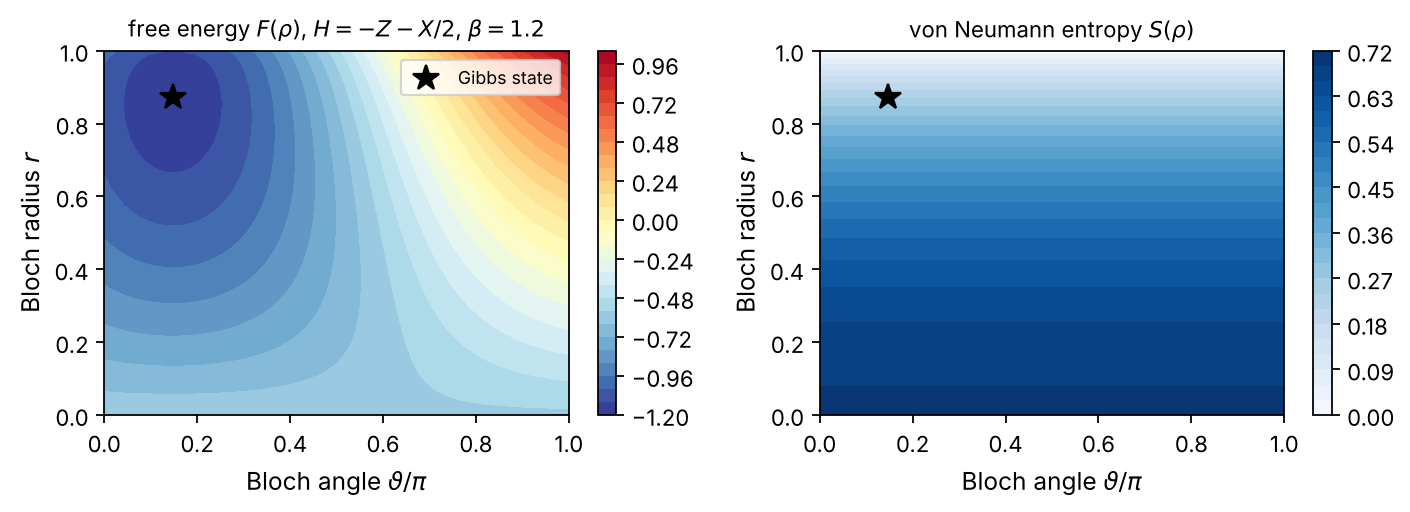

In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter5/gibbs.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter5').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


exact RBM gradient against finite differences: max |diff| = 3.7e-10

Table 5-cd: KL(target || model) after 3000 gradient steps, lr = 0.5 (PCD: 0.2, 50 chains)
            target  n_h     exact      CD-1     CD-10       PCD    time


 XOR (parity, n=2)    2    0.0044    0.0967    0.0228    0.0331    4.7s


  bars and stripes    4    0.0230    0.0823    0.0531    0.4814    4.9s


figure rbm written


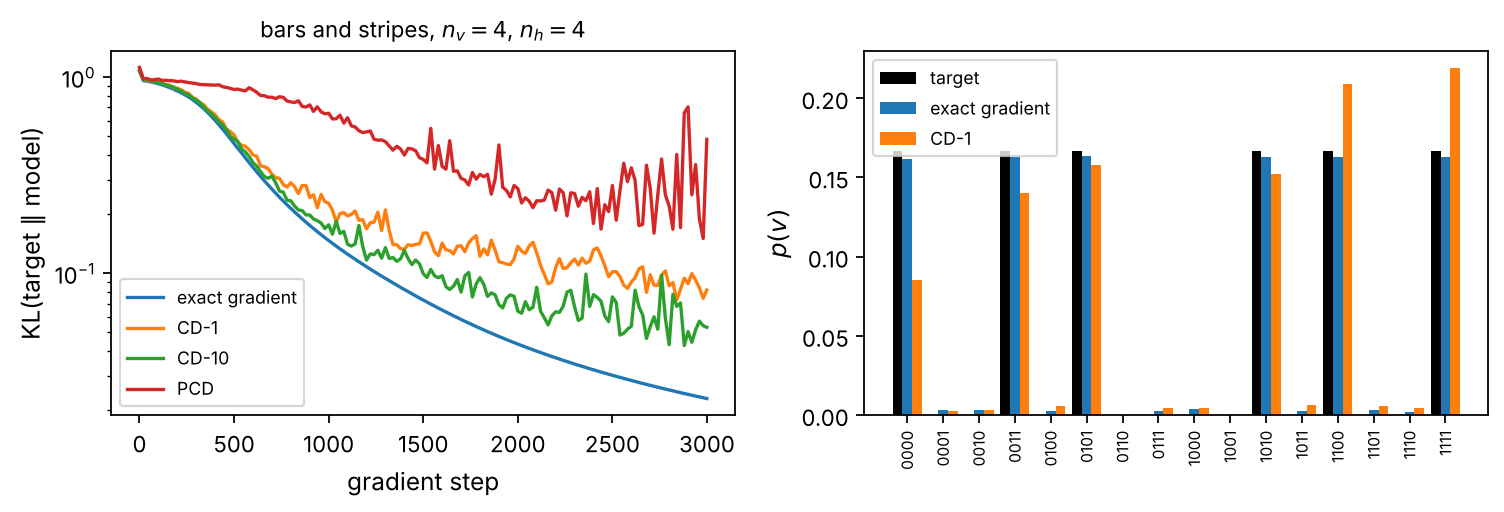

In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter5/rbm.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter5').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter5/qbm.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter5').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


RQBM, 2 visible + 2 hidden qubits, random parameters, XOR target
  term   exact (Duhamel)   finite diff.  bound gradient
    Z0         -0.060300      -0.060300       -0.061133
    Z1         -0.141716      -0.141716       -0.143026
    Z2          0.081718       0.081718        0.083694
    Z3          0.029148       0.029148        0.029801
    X0         -0.009442      -0.009442       -0.227435
    X1          0.005532       0.005532        0.173332
    X2          0.017987       0.017987        0.019094
    X3         -0.002691      -0.002691       -0.001743
  Z0Z2          0.196026       0.196026        0.206809
  Z0Z3         -0.013928      -0.013928       -0.004916
  Z1Z2          0.202632       0.202632        0.211565
  Z1Z3          0.465294       0.465294        0.479711
no transverse fields: max |exact - bound| = 1.1e-16
relative-entropy gradient against finite differences: max |diff| = 5.7e-10


Table 5-classical: NLL - entropy of the target = KL(target || model) after training with Adam
           target  n_v  n_h  steps    lr  RBM (1000 steps)   QBM, no X   QBM exact   QBM bound    time


              XOR    2    2    300   0.1            0.0004      0.0003      0.0002      0.0002    2.9s


 bars and stripes    4    3    200  0.05            0.0028      0.0074      0.0082      0.0099   78.6s

XOR, model trained with the exact gradient: transverse fields [ 0.    -0.     0.018  0.   ] (qubits 0-3)
KL against a common transverse field Gamma: 0.0002 at Gamma = 0, 0.0002 at Gamma = 0.00, 0.1085 at Gamma = 2
visible state of the trained XOR model: diagonal [4.999e-01 1.000e-04 1.000e-04 4.999e-01], sum of |off-diagonal| elements 0.0000
bound-trained model: transverse fields [-0.    -0.     0.017 -0.   ], visible diagonal [4.999e-01 1.000e-04 1.000e-04 4.999e-01]


figure classical written


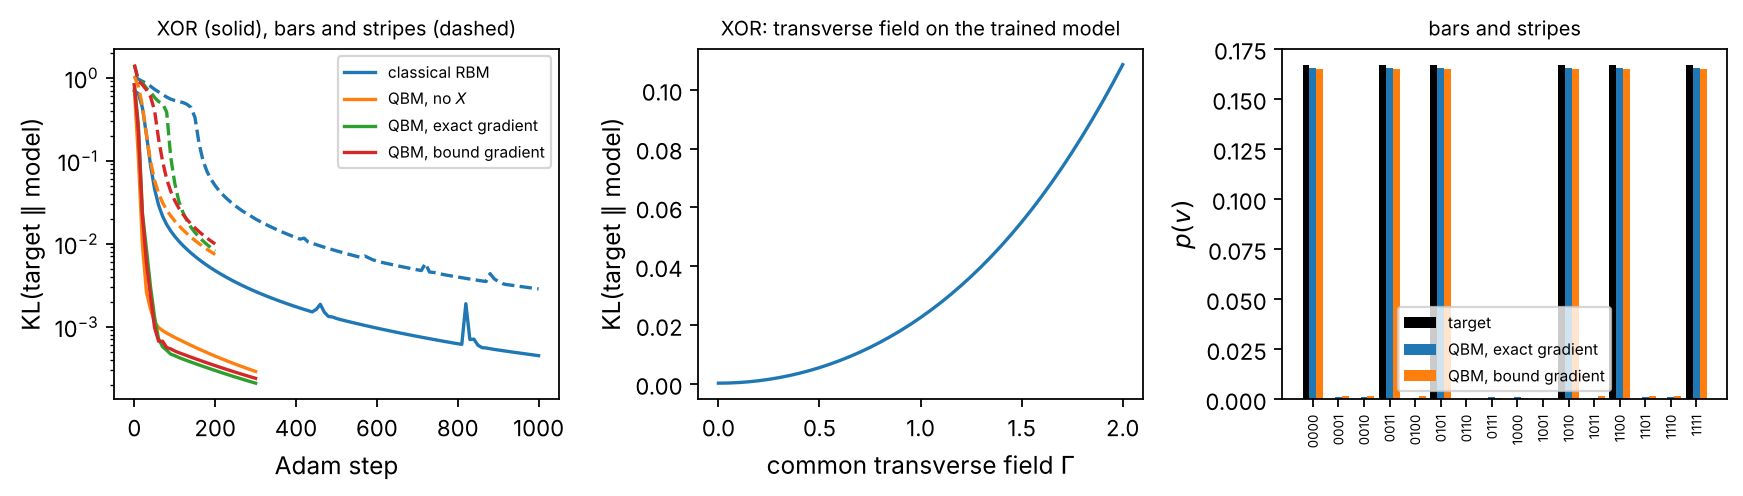

In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter5/classical_data.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter5').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Table 5-hamlearn: couplings of the target Hamiltonian and of the trained QBM (3 qubits, beta = 1)
  term    target   learned
    Z0   -0.5214   -0.5214
    Z1   -0.1398   -0.1398
    Z2    1.3310    1.3310
    X0    0.5273    0.5273
    X1   -1.3131   -1.3131
    X2   -0.0042   -0.0042
  Z0Z1   -0.4988   -0.4988
  Z1Z2    0.1189    0.1189
relative entropy 1.1288 -> 0.00e+00, fidelity 1.00000000, max |theta - theta*| = 1.6e-09 (0.2 s)

XXZ-chain target (tilted field, next-nearest-neighbour Z Z), beta = 1.0: three model families, 400 Adam steps
                 model    P  S(rho_t||rho)   fidelity  diagonal KL
    Z + ZZ (classical)    5        0.94102   0.539826      0.07516


            Z + X + ZZ    8        0.86078   0.571801      0.07575


  Z + X + ZZ + XX + YY   12        0.02033   0.990646      0.01294


figure quantumdata written


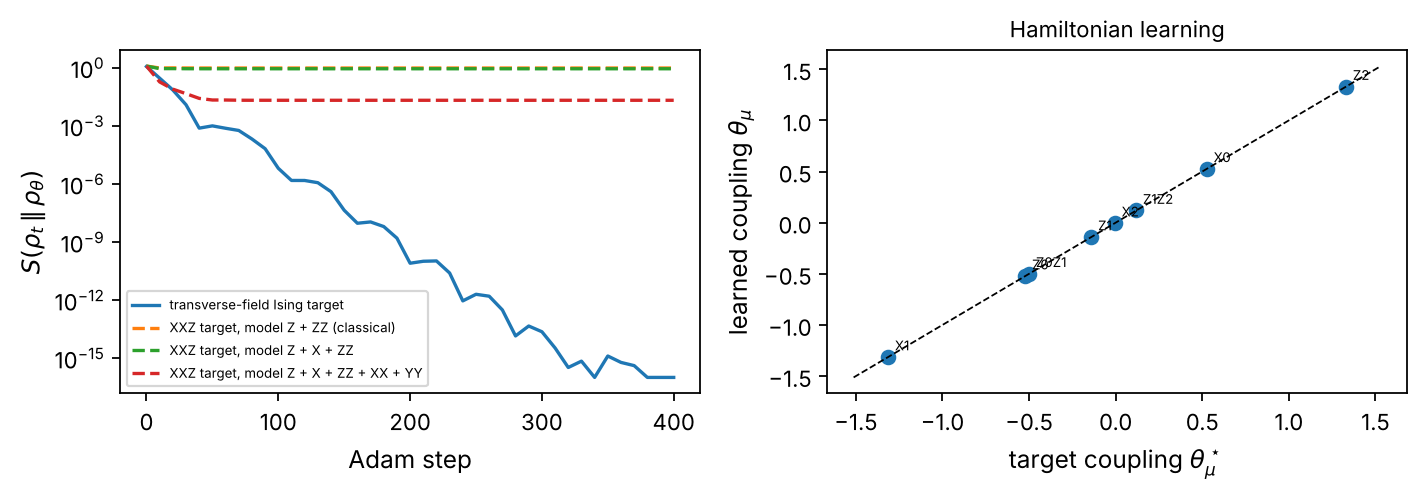

In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter5/quantum_data.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter5').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


free-energy gradient against finite differences: max |diff| = 3.2e-10

Table 5-vqt: variational Gibbs states of the transverse-field Ising chain, n = 3, h = 1 (300 Adam steps, lr 0.05)
 beta   latent   L    P    F_exact      F_vqt  F - F_exact   fidelity   S_vqt  S_exact   time


  1.0  product   1    9   -3.94419   -3.68842     2.56e-01   0.857190   0.678    0.995   0.8s


  1.0  product   2   15   -3.94419   -3.85558     8.86e-02   0.954488   0.845    0.995   1.1s


  1.0  product   3   21   -3.94419   -3.86777     7.64e-02   0.967747   0.887    0.995   1.6s


  1.0     full   1   14   -3.94419   -3.75879     1.85e-01   0.911664   0.858    0.995   0.7s


...

  3.0  product   3   21   -3.51647   -3.48592     3.05e-02   0.971999   0.185    0.245   1.8s


  3.0     full   1   14   -3.51647   -3.48258     3.39e-02   0.958353   0.074    0.245   0.6s


  3.0     full   2   20   -3.51647   -3.50346     1.30e-02   0.990986   0.196    0.245   1.1s


  3.0     full   3   26   -3.51647   -3.50758     8.89e-03   0.995714   0.236    0.245   1.5s


figure vqt written


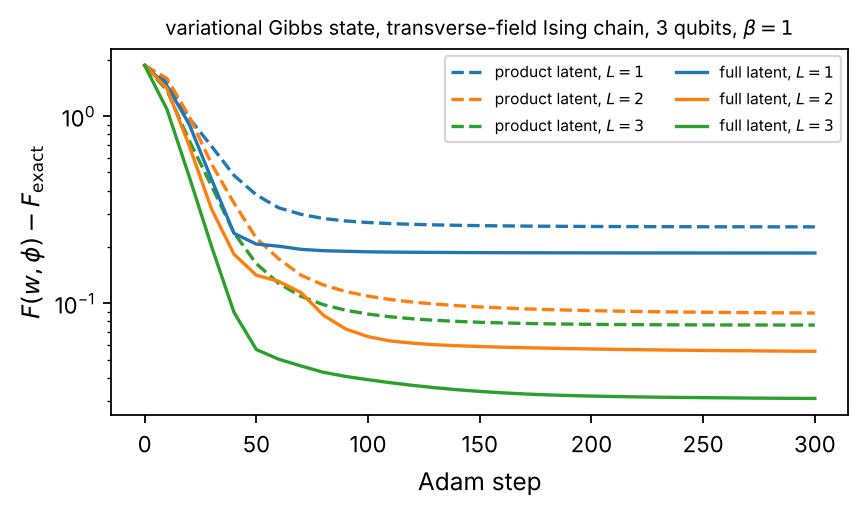

In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter5/vqt.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter5').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
